# HW3 — Human / AI / Fusion text classification

All logic is in `hw3_text_detection.py`; this notebook runs the pipeline stage by stage.
Runs on **Google Colab** and **locally** (VS Code) without changes: paths and device are detected automatically.

Heavy stages save their results to `runs/<name>/` on Google Drive. Set a toggle to `False`
to skip a stage and load its saved results instead.

## 0. Setup

In [1]:
# ---------------- toggles ----------------
RUN_EDA = False
RECOMPUTE_GROUPS = False   # cached in splits/groups.csv
RECOMPUTE_SPLIT = False    # cached in splits/split_v1.csv (always recomputed with new groups)
RUN_BASELINE = False        # False -> only load runs/baseline_tfidf (models already saved are never refitted)
CACHE_FEATURES = True      # save TF-IDF matrices to runs/baseline_tfidf/features (~3-4 GB on Drive)
RUN_ENCODER = True         # False -> load runs/encoder_xlmr_chunks

SUBSAMPLE_N = 40_000       # fixed subsample of whole groups; 20% of it is validation
BASELINE_RUN = "baseline_tfidf"
ENCODER_RUN = "encoder_xlmr_chunks"

# ---------------- environment ----------------
REPO_URL = "https://github.com/Rein-h/pavlunyshyn_hw3_AI.git"
LOCAL_ROOT = r"G:\My Drive\hw3"                    # local run only: folder that contains data/

In [2]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if os.path.exists(REPO_DIR):
        !git -C {REPO_DIR} pull -q
    else:
        !git clone -q {REPO_URL} {REPO_DIR}
    %pip install -q -r {REPO_DIR}/requirements.txt
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive


In [3]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import hw3_text_detection as hw
importlib.reload(hw)  # picks up a new version of the .py after git pull

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
hw.seed_everything(hw.SEED)
RECOMPUTE_SPLIT = RECOMPUTE_SPLIT or RECOMPUTE_GROUPS

ENC_CFG = hw.EncoderConfig(
    model_name="xlm-roberta-base",
    max_len=512,          # tokens per window
    overlap=64,           # overlap of neighbouring windows
    train_windows=1,      # random windows per text per epoch
    max_eval_windows=8,   # windows averaged per text at inference
    epochs=2,
    lr=2e-5,
    freeze_embeddings=True,   # embedding layer is not trained: checkpoint ~1 GB instead of ~3.3 GB
    checkpoint_minutes=15,    # save progress every 15 min inside an epoch
)

paths = hw.get_paths(local_root=LOCAL_ROOT, colab_root="/content/drive/MyDrive/hw3")
hw.describe_environment()

{'colab': True,
 'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'gpu': 'Tesla T4',
 'gpu_mem_gb': 14.6}

## 1. Data

In [4]:
train, test, sample = hw.load_data(paths)
hw.data_overview(train, test, sample)

,train,test
rows,272352,25000
unique ids,272352,25000
empty texts,0,0
duplicated texts (within set),0,0
texts also in other set,0,0
missing values,0,0
sample_submission ids == test ids (same order),1,


## 2. EDA
### 2.1 Class balance by language and domain

In [5]:
if RUN_EDA:
    tables = hw.class_balance_tables(train)
    display(tables["label"], tables["lang x label"], tables["domain x label"])
    hw.plot_class_balance(train)
    plt.show()

### 2.2 Text lengths

In [6]:
if RUN_EDA:
    hw.plot_lengths(train)
    plt.show()
    display(hw.length_table(train))

### 2.3 Length in encoder tokens
Share of texts that do not fit into one encoder window — the reason the encoder works on windows (chunks).

In [7]:
if RUN_EDA:
    display(hw.token_length_stats(train["text"], ENC_CFG.model_name, ENC_CFG.max_len))

### 2.4 Examples of each class

In [8]:
if RUN_EDA:
    hw.show_examples(train, n_chars=300)

### 2.5 Train vs. test distribution

In [9]:
if RUN_EDA:
    display(hw.compare_train_test(train, test))

## 3. Groups of versions and the fixed validation split
A human text and its ai / fusion versions are near-duplicates and are always on the same side of the
train/test split. Groups are rebuilt from shared word 5-grams; the validation split keeps every group
whole, so validation mimics the test split.

In [10]:
train["group"] = hw.load_or_make_groups(train, paths, recompute=RECOMPUTE_GROUPS)
hw.group_composition(train)

,groups,texts,max_size
labels in group,,,
ai,113817,118494,36
human+fusion,51177,130160,147
human,10873,10959,7
fusion,3882,4604,6
human+ai+fusion,1020,7604,656
ai+fusion,96,428,22
human+ai,46,103,5


In [11]:
tr, va = hw.load_or_make_split(train, paths, n_samples=SUBSAMPLE_N, recompute=RECOMPUTE_SPLIT)
# the same fingerprint in every session = exactly the same train/val rows
print("split fingerprint:", hw.split_fingerprint(tr, va, test))
hw.split_summary(tr, va)

split fingerprint: 0932afb975


,train,val
label=ai,0.451,0.451
label=fusion,0.307,0.301
label=human,0.242,0.248
lang=en-EN,0.805,0.791
lang=de-DE,0.195,0.209
domain=student_essays,0.201,0.185
domain=bundestag,0.193,0.207
domain=cnn_news,0.163,0.166
domain=blog_authorship_corpus,0.150,0.147
domain=house_of_commons,0.113,0.116


### 3.1 What makes fusion different
Every ai / fusion text that has a human version in its group is compared with that human version:
overlap of word 3-grams, share of sentences copied verbatim, relative length.

In [12]:
if RUN_EDA:
    cmp = hw.compare_with_human_version(train)
    display(cmp.groupby("label").median().round(3))
    hw.plot_human_version_comparison(cmp)
    plt.show()
    hw.show_group_example(train, n_chars=400)

### Free memory
From here on only the subsample (`tr`, `va`) and `test` are needed. The full train set (~272k texts)
is removed from RAM; to use it again, rerun the notebook from section 1.

In [13]:
import gc
del train
gc.collect()

21

## 4. Baseline: TF-IDF + linear models
TF-IDF is fitted on the train split only. Small grid search (feature set × model × C) on the fixed validation split.

Every model is saved to `runs/baseline_tfidf/grid/<features>_<model>_C<C>/` (metrics + val/test probabilities)
right after it is fitted; TF-IDF matrices are cached in `runs/baseline_tfidf/features/`.
The grid runs in three cells, one per feature set. After a crash, rerun from the cell that crashed: saved models are skipped.

In [14]:
BL_DIR = paths.runs / BASELINE_RUN
BASELINE_MODELS = {"logreg": [1.0, 10.0], "linsvc": [0.1, 1.0]}   # model -> values of C

def run_feature_set(features):
    if RUN_BASELINE:
        hw.run_baseline_grid(tr, va, test, BL_DIR, cache_features=CACHE_FEATURES,
                             grid={"features": [features], "models": BASELINE_MODELS})

### 4.1 Word n-grams (1–2)

In [15]:
run_feature_set("word")

### 4.2 Character n-grams (3–5)

In [16]:
run_feature_set("char")

### 4.3 Word + character n-grams

In [17]:
run_feature_set("word+char")

### 4.4 Grid results and the best baseline
The best model of the grid is copied to `runs/baseline_tfidf/` (metrics, probabilities, `submission.csv`).

In [18]:
bl_config = hw.finalize_baseline(BL_DIR, va, test, sample)
bl_run = hw.load_run(BL_DIR)
pd.read_csv(BL_DIR / "grid.csv")

,model_id,features,model,C,macro_f1,F1 human,F1 ai,F1 fusion,fit_sec
0,word+char_logreg_C10.0,word+char,logreg,10.0,0.8756,0.8300,0.9794,0.8175,284.4
1,char_logreg_C10.0,char,logreg,10.0,0.8712,0.8198,0.9778,0.8159,193.3
2,word+char_logreg_C1.0,word+char,logreg,1.0,0.8700,0.8237,0.9784,0.8077,260.0
3,word+char_linsvc_C1.0,word+char,linsvc,1.0,0.8616,0.8172,0.9756,0.7920,65.0
4,char_logreg_C1.0,char,logreg,1.0,0.8614,0.8106,0.9738,0.7997,187.4
5,char_linsvc_C1.0,char,linsvc,1.0,0.8560,0.8073,0.9729,0.7878,41.8
6,word_logreg_C10.0,word,logreg,10.0,0.8534,0.8027,0.9768,0.7805,110.0
7,word+char_linsvc_C0.1,word+char,linsvc,0.1,0.8475,0.8073,0.9707,0.7646,30.0
8,word_logreg_C1.0,word,logreg,1.0,0.8391,0.7870,0.9722,0.7581,80.2
9,char_linsvc_C0.1,char,linsvc,0.1,0.8343,0.7914,0.9641,0.7475,23.1


Baseline word+char_logreg_C10.0: val macro-F1 = 0.8756


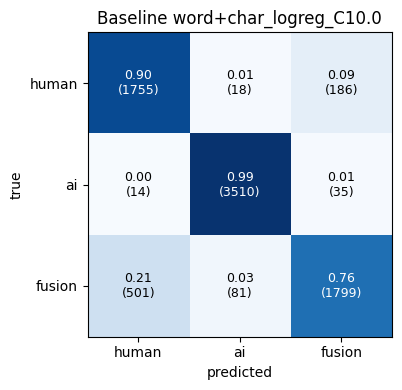

,precision,recall,f1
human,0.7731,0.8959,0.8300
ai,0.9726,0.9862,0.9794
fusion,0.8906,0.7556,0.8175


macro_f1
lang   de-DE                     0.8834
       en-EN                     0.8731
domain arxiv_papers              0.8862
       blog_authorship_corpus    0.7642
       bundestag                 0.8833
       cnn_news                  0.8960
       euro_court_cases          0.9192
       gutenberg                 0.7539
       house_of_commons          0.8908
       student_essays            0.8946

In [19]:
bl_per_class, bl_by, _ = hw.run_report(bl_run, va, f"Baseline {bl_config['model_id']}")
plt.show()
display(bl_per_class, bl_by)

## 5. Encoder: fine-tuned multilingual transformer
Long texts are split into overlapping windows of `max_len` tokens. Training sees a random window of
each text (a new one every epoch); prediction averages the probabilities of up to `max_eval_windows`
windows that cover the text. The best epoch is selected on the same validation split as the baseline.

If the Colab session dies, rerun this cell: training resumes from the last finished epoch.

In [20]:
ENC_DIR = paths.runs / ENCODER_RUN
if RUN_ENCODER:
    enc = hw.train_encoder(tr, va, test, ENC_CFG, ENC_DIR)
    enc_sub = hw.make_submission(test["id"], np.array(hw.LABELS)[enc["test_proba"].argmax(1)], sample)
    hw.save_run(ENC_DIR, enc["metrics"], enc["config"], va["id"], enc["val_proba"],
                test["id"], enc["test_proba"], enc_sub)

enc_run = hw.load_run(ENC_DIR)
pd.DataFrame(enc_run["metrics"]["history"])

device=cuda, batch=16 x accum 1, freeze_embeddings=True


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

... (9 outputs left out)

epoch 2: train loss 0.2573, val macro-F1 0.8760 (16.5 min)


tokenize:   0%|          | 0/25 [00:00<?, ?it/s]

test:   0%|          | 0/1639 [00:00<?, ?it/s]

,epoch,train_loss,val_macro_f1,minutes
0,1,0.427318,0.885698,15.820360
1,2,0.257253,0.876010,16.521049


Encoder xlm-roberta-base: val macro-F1 = 0.8857


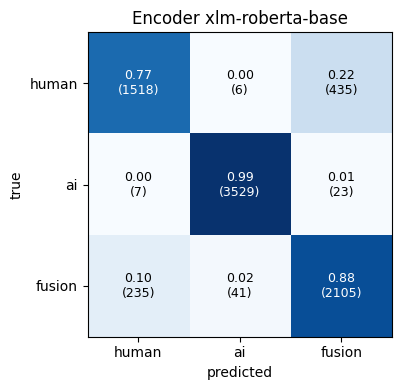

,precision,recall,f1
human,0.8625,0.7749,0.8163
ai,0.9869,0.9916,0.9892
fusion,0.8213,0.8841,0.8515


macro_f1
lang   de-DE                     0.9093
       en-EN                     0.8784
domain arxiv_papers              0.6188
       blog_authorship_corpus    0.8140
       bundestag                 0.9093
       cnn_news                  0.8966
       euro_court_cases          0.8296
       gutenberg                 0.7880
       house_of_commons          0.9181
       student_essays            0.9119

In [21]:
enc_per_class, enc_by, _ = hw.run_report(enc_run, va, f"Encoder {ENC_CFG.model_name}")
plt.show()
display(enc_per_class, enc_by)

## 6. Baseline vs. encoder (same validation split)
Submission files: `runs/<run name>/submission.csv` on Google Drive.

In [22]:
hw.compare_runs(paths, [BASELINE_RUN, ENCODER_RUN], va)

,macro_f1,F1 human,F1 ai,F1 fusion,macro_f1 de-DE,macro_f1 en-EN
baseline_tfidf,0.8756,0.8300,0.9794,0.8175,0.8834,0.8731
encoder_xlmr_chunks,0.8857,0.8163,0.9892,0.8515,0.9093,0.8784
